# Quality comparison: RL orchestrator vs HybridLLM (MMLU, accuracy-based)

Same comparison as the MixInstruct notebook, but on a task where quality needs no BARTScore:
**MMLU** (multiple choice, 4 options). Instead of generating free text, each model is scored with
**one forward pass per question** -- no decoding loop, no judge model. This also means the quality
table can be precomputed **once, for all 5 models, over the whole pool AND the held-out validation
set** -- RL's reward lookup, HybridLLM's label-building (any pair), and final evaluation all just
index into this one cached table.

Pipeline (every expensive step is cached to `CKPT_DIR` and resumes if interrupted):

1. Load MMLU; build one shared prompt per question; **verify each model's A/B/C/D token ids
   carefully** (this is the step most likely to silently go wrong).
2. Score all 5 models on (pool + held-out) with one forward pass each -- correctness (0/1) and the
   probability assigned to the correct letter (soft quality). Print the per-model accuracy table
   **first** and flag it if `flan-t5-xl` matches or beats Llama-2 (it would mean "bigger = better"
   doesn't hold on this task).
3. **RL**: online learning over the whole pool, reward read directly from the precomputed table
   (no model calls in the loop itself -- this is the fast part).
4. **HybridLLM**: for each of the 3 pairs, build labels from the SAME table slice (first ~9.5k pool
   questions), train a DeBERTa-v3-small router per pair/label-type, sweep the threshold on the
   held-out set.
5. Compare: cost-accuracy curves, baselines/oracles, matched-cost comparison with bootstrap CIs.

**Run order:** first set `DRY_RUN = True` and run everything end to end (a couple of minutes).
Then set it to `False` and re-run.
**GPU:** shut down any other notebook kernel first so GPU 0 has free memory. One model is loaded
at a time; peak use should be well under 20 GB (forward-pass-only, no generation).
**Namespacing:** this is a separate task from MixInstruct -- every new cache/result file uses an
`mmlu_` prefix, so nothing from the earlier RL/HybridLLM runs (`rl_training_state`, `rl_results.json`,
etc.) is touched or overwritten.

## Step 0: preflight (run this first; it stops early with the exact fix if anything is missing)

In [1]:
import sys, importlib, os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # must be set before torch is imported

REQUIRED = {"numpy": "numpy", "torch": "torch", "datasets": "datasets", "transformers": "transformers",
            "matplotlib": "matplotlib", "sentencepiece": "sentencepiece", "google.protobuf": "protobuf"}
missing = []
for mod, pip_name in REQUIRED.items():
    try:
        importlib.import_module(mod)
    except Exception:
        missing.append(pip_name)
if missing:
    raise RuntimeError("Missing packages: " + ", ".join(missing) +
        "\nInstall from a TERMINAL (pip inside Jupyter is blocked on this server), then restart the kernel:\n"
        "  " + sys.executable + " -m pip install " + " ".join(missing))

import torch
if torch.cuda.is_available():
    free_gb = torch.cuda.mem_get_info()[0] / 1e9
    print(f"free GPU memory: {free_gb:.1f} GB")
    if free_gb < 15:
        print("WARNING: less than ~15 GB free. Shut down other notebook kernels (check nvidia-smi) before the real run.")
else:
    print("WARNING: no GPU visible to torch")
print("preflight OK: packages present.")

free GPU memory: 44.7 GB
preflight OK: packages present.


## Setup

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gc, math, json, random, pickle, shutil, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM, AutoModel)
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| free GB:", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

WORK_DIR = os.path.expanduser("~/hybridllm_project")
CKPT_DIR = os.path.join(WORK_DIR, "ckpt_shared")       # same shared folder as the other notebooks
OUTPUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_ckpt(name, obj):
    with open(f"{CKPT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)

def load_ckpt(name):
    path = f"{CKPT_DIR}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def load_with_retry(model_class, model_id, **kwargs):
    try:
        return model_class.from_pretrained(model_id, **kwargs)
    except Exception as e:
        print(f"  [{model_id}] load failed ({type(e).__name__}); clearing cache and re-downloading...")
        cache_root = os.path.join(os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface")), "hub")
        target = os.path.join(cache_root, "models--" + model_id.replace("/", "--"))
        if os.path.exists(target):
            shutil.rmtree(target)
        return model_class.from_pretrained(model_id, force_download=True, **kwargs)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("helpers ready.")

Device: cuda
GPU: NVIDIA L40S | free GB: 44.7
helpers ready.


## Config

In [3]:
DRY_RUN = False           # True = tiny smoke test (a couple of minutes). Set False for the real run.
TASK = "mmlu"             # every new cache/result file is prefixed with this -- never touches the MixInstrud/RL files

PAIRS = [   # same three pairs as the cost analysis and the MixInstruct notebook
    ("large_gap",  "flan-t5-small", "llama-2-7b-chat"),
    ("medium_gap", "flan-t5-large", "llama-2-7b-chat"),
    ("small_gap",  "flan-t5-xl",    "llama-2-7b-chat"),
]
N_TRAIN_HYB = 9500        # HybridLLM label-building questions, drawn from the pool
MAX_PROMPT_LEN = 512      # MMLU prompts are short; generous headroom for long questions/choices
SCORE_BS = {"flan-t5-small": 128, "flan-t5-base": 128, "flan-t5-large": 64, "flan-t5-xl": 32, "llama-2-7b-chat": 32}
CHUNK_SIZE = 500          # questions per checkpoint during scoring
ROUTER_EPOCHS, ROUTER_LR, ROUTER_BATCH = 6, 2e-5, 16
ROUTER_ID = "microsoft/deberta-v3-small"
LAMBDA_EVAL = 0.5         # FIXED yardstick for the "utility" metric -- used to judge every method
                          # (RL at any trained lambda, every HybridLLM pair, every baseline) fairly and consistently.
                          # Never changes, regardless of what lambda an RL policy was trained with.
EPS_START, EPS_END = 0.30, 0.05
RL_CHUNK_SIZE = 500       # RL checkpoint frequency (steps)

# Lambda values to actually RETRAIN the RL orchestrator at (not just reweight post-hoc) -- each
# value changes the reward during training, so exploration/reinforcement genuinely differs, which
# matters if a previous run (e.g. lambda=0.5 on MixInstruct) mostly chose the large model: that
# policy's cheap-model value estimates would be undertrained, making a post-hoc reweighting of IT
# alone unreliable at the cheap end. Real retraining avoids that.
LAMBDA_TRAIN_GRID = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]

# dense evaluation-time reweighting sweep, applied ONLY to the winning trained policy at the end
# (same construction as the MixInstruct notebook, ~55 points) -- a smooth curve around the real,
# independently-trained grid points above, not a substitute for them.
LAMBDAS = sorted(set(np.round(np.concatenate([np.linspace(0, 1, 26), np.linspace(1.25, 8, 28), [0.5]]), 3).tolist()))

if DRY_RUN:
    N_TRAIN_HYB, ROUTER_EPOCHS = 80, 1
    LAMBDA_TRAIN_GRID = [0.5, 2.0]
TAG = ("dry_" if DRY_RUN else "") + TASK + "_"     # keeps dry-run caches separate, and separate from MixInstruct's

MODEL_IDS = [
    ("flan-t5-small",   "google/flan-t5-small",            False, 80e6),
    ("flan-t5-base",    "google/flan-t5-base",             False, 250e6),
    ("flan-t5-large",   "google/flan-t5-large",            False, 780e6),
    ("flan-t5-xl",      "google/flan-t5-xl",               False, 3e9),
    ("llama-2-7b-chat", "NousResearch/Llama-2-7b-chat-hf", True,  7e9),
]
MODEL_NAMES = [m[0] for m in MODEL_IDS]
PARAMS = np.array([m[3] for m in MODEL_IDS])
COSTS = PARAMS / PARAMS.max()
N_ARMS = len(MODEL_IDS)
for _lbl, _S, _L in PAIRS:
    assert _S in MODEL_NAMES and _L in MODEL_NAMES and _S != _L, f"{_lbl}: {_S}/{_L} not in model set"

print(f"pairs: {PAIRS}\nlambda_train_grid={LAMBDA_TRAIN_GRID} | lambda_eval={LAMBDA_EVAL} | DRY_RUN={DRY_RUN} | {len(LAMBDAS)} dense sweep points")

pairs: [('large_gap', 'flan-t5-small', 'llama-2-7b-chat'), ('medium_gap', 'flan-t5-large', 'llama-2-7b-chat'), ('small_gap', 'flan-t5-xl', 'llama-2-7b-chat')]
lambda_train_grid=[0.05, 0.1, 0.25, 0.5, 1.0, 2.0] | lambda_eval=0.5 | DRY_RUN=False | 55 dense sweep points


## Data: MMLU pool and held-out validation set

`pool` (MMLU `test` split, ~14k) is what RL streams over and what HybridLLM draws its label-building
questions from. `holdout` (MMLU `validation` split, 1,531) is scored but never trained on by either
system -- the final comparison in Step 4 runs on `holdout` only.

Prompt format is the standard MMLU zero-shot style (subject-aware instruction line, then the
question, choices A-D, then "Answer:"). This is **zero-shot**, not the paper's original 5-shot
setup -- noted here explicitly since it affects the absolute accuracy numbers (relative comparisons
between models/routers are unaffected, since every model sees the identical prompt format).

In [4]:
def load_mmlu():
    try:
        ds = load_dataset("cais/mmlu", "all")
        return ds["test"], ds["validation"]
    except Exception as e:
        print(f"cais/mmlu failed ({type(e).__name__}: {e}); trying hendrycks_test ...")
        ds = load_dataset("hendrycks_test", "all")
        return ds["test"], ds["validation"]

ds_test, ds_val = load_mmlu()
print(f"MMLU loaded: test={len(ds_test)}  validation={len(ds_val)}")

def to_example(ex):
    return {"question": ex["question"], "choices": list(ex["choices"]), "answer": int(ex["answer"]),
            "subject": ex.get("subject", "")}

def build_prompt(ex):
    subject_fmt = (ex["subject"] or "general knowledge").replace("_", " ")
    letters = "ABCD"
    choice_lines = "\n".join(f"{letters[i]}. {ex['choices'][i]}" for i in range(4))
    return (f"The following is a multiple choice question (with answer) about {subject_fmt}.\n\n"
            f"{ex['question']}\n{choice_lines}\nAnswer:")

pool = load_ckpt(f"{TAG}pool_examples")
holdout = load_ckpt(f"{TAG}holdout_examples")
if pool is None or holdout is None:
    order = list(range(len(ds_test))); random.Random(SEED + 1).shuffle(order)
    pool = [to_example(ds_test[i]) for i in order]
    holdout = [to_example(ds_val[i]) for i in range(len(ds_val))]   # validation set used whole, in original order
    if DRY_RUN:
        pool, holdout = pool[:200], holdout[:100]
    for ex in pool + holdout:
        ex["prompt"] = build_prompt(ex)
    save_ckpt(f"{TAG}pool_examples", pool)
    save_ckpt(f"{TAG}holdout_examples", holdout)

hyb_pool = pool[:N_TRAIN_HYB]   # HybridLLM label-building slice -- just the first N_TRAIN_HYB of the SAME pool
print(f"pool={len(pool)}  holdout={len(holdout)}  hybrid-train slice={len(hyb_pool)}")
print("\nexample prompt:\n" + pool[0]["prompt"])
print(f"\n(correct answer: {'ABCD'[pool[0]['answer']]})")

MMLU loaded: test=14042  validation=1531
pool=14042  holdout=1531  hybrid-train slice=9500

example prompt:
The following is a multiple choice question (with answer) about security studies.

What has been the impact of nuclear deterrence on international politics post-Cold War?
A. There is a developing scholarly trend toward proliferation pessimism, a pattern which has gained momentum rather than subsided with the end of the Cold War. There is concern that accidental war may occur, either through misperception, psychological or technical problems that can lead to spiralling tensions which result in a failure of deterrence policy. In addition, normal accidents resulting from the inability of a state to capably anticipate human-machine interactions in the complexities of the international (and anarchical) system may also occur.
B. Proliferation optimists dispute the claim that nuclear technology leads to a propensity of the holding actor towards war. They do concede that there is the ris

## Letter-token-id verification (do this carefully -- this is the step most likely to silently break)

Two different mechanisms, matching the two architectures:
- **FLAN-T5** (encoder-decoder): the decoder generates completely fresh, so the right check is
  "does `tokenizer.encode(letter)` alone give exactly one token?" (SentencePiece's own convention
  prepends a space-marker to a standalone string, so this works without manually adding a space).
- **Llama-2** (causal): the letter is read as the model's *next-token* prediction continuing the
  literal string the prompt already ends with (`"...Answer:"`). The only trustworthy check is
  **in-context**: tokenize a real sample prompt, then tokenize the same prompt with `" " + letter`
  appended, and confirm it added *exactly one* token -- that token id is the ground truth for this
  tokenizer, regardless of SentencePiece edge cases.

Both are asserted, not assumed -- if a tokenizer doesn't behave as expected, this stops with a clear
error rather than silently scoring wrong token ids.

In [5]:
def get_t5_letter_ids(tok):
    ids = {}
    for letter in "ABCD":
        enc = tok.encode(letter, add_special_tokens=False)
        assert len(enc) == 1, f"T5 tokenizer: letter {letter!r} is not a single token: {enc} -> {tok.convert_ids_to_tokens(enc)}"
        ids[letter] = enc[0]
    return ids

def get_causal_letter_ids(tok, sample_prompt):
    base = tok.encode(sample_prompt, add_special_tokens=False)
    ids = {}
    for letter in "ABCD":
        full = tok.encode(sample_prompt + " " + letter, add_special_tokens=False)
        assert len(full) == len(base) + 1, (
            f"Llama tokenizer: appending {letter!r} did not add exactly one token "
            f"(base_len={len(base)}, full_len={len(full)}, new tokens={tok.convert_ids_to_tokens(full[len(base):])})"
        )
        ids[letter] = full[-1]
    return ids

LETTER_IDS = {}
sample_prompt = pool[0]["prompt"]
for name, model_id, is_causal, _ in MODEL_IDS:
    tok = AutoTokenizer.from_pretrained(model_id)      # tokenizer only -- no model weights loaded here
    if is_causal:
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        tok.padding_side = "left"
        LETTER_IDS[name] = get_causal_letter_ids(tok, sample_prompt)
    else:
        LETTER_IDS[name] = get_t5_letter_ids(tok)
    readable = {l: (i, tok.convert_ids_to_tokens([i])[0]) for l, i in LETTER_IDS[name].items()}
    print(f"{name:>16}: {readable}")
    del tok

print("\nletter ids verified for all 5 tokenizers.")

   flan-t5-small: {'A': (71, '▁A'), 'B': (272, '▁B'), 'C': (205, '▁C'), 'D': (309, '▁D')}
    flan-t5-base: {'A': (71, '▁A'), 'B': (272, '▁B'), 'C': (205, '▁C'), 'D': (309, '▁D')}
   flan-t5-large: {'A': (71, '▁A'), 'B': (272, '▁B'), 'C': (205, '▁C'), 'D': (309, '▁D')}
      flan-t5-xl: {'A': (71, '▁A'), 'B': (272, '▁B'), 'C': (205, '▁C'), 'D': (309, '▁D')}
 llama-2-7b-chat: {'A': (319, '▁A'), 'B': (350, '▁B'), 'C': (315, '▁C'), 'D': (360, '▁D')}

letter ids verified for all 5 tokenizers.


## Scoring utilities (one forward pass per question, one model in memory at a time)

No generation, no decoding loop: FLAN-T5 reads its decoder's first-step logits; Llama-2 reads its
last-position (next-token) logits, exactly like the RL/MixInstruct notebooks' causal generation did,
just without the autoregressive loop. Both reduce to "logits over 4 letter-token ids, softmaxed."

In [6]:
def load_agent(name):
    _, model_id, is_causal, params = next(m for m in MODEL_IDS if m[0] == name)
    tok = AutoTokenizer.from_pretrained(model_id)
    if is_causal:
        tok.pad_token = tok.eos_token          # always reuse eos: a shipped/added pad token can sit outside the embedding table
        tok.padding_side = "left"
        model = load_with_retry(AutoModelForCausalLM, model_id, torch_dtype=torch.float16).to(DEVICE)
        n_emb = model.get_input_embeddings().num_embeddings
        print(f"  [{name}] pad_token_id={tok.pad_token_id}  embedding rows={n_emb}  len(tokenizer)={len(tok)}")
        assert tok.pad_token_id < n_emb, "pad token id is outside the embedding table"
    else:
        model = load_with_retry(AutoModelForSeq2SeqLM, model_id, torch_dtype=torch.float16).to(DEVICE)
    model.eval()
    return {"name": name, "tok": tok, "model": model, "causal": is_causal}

def free_agent(entry):
    del entry["model"], entry["tok"]
    free_gpu()

OOV_REPLACED = {"n": 0}

@torch.no_grad()
def score_batch(entry, prompts, letter_ids):
    tok, model = entry["tok"], entry["model"]
    enc = tok(prompts, return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
    letter_logit_ids = [letter_ids[l] for l in "ABCD"]
    if entry["causal"]:
        n_emb = model.get_input_embeddings().num_embeddings
        bad = enc["input_ids"] >= n_emb
        if bad.any():
            enc["input_ids"][bad] = tok.unk_token_id if tok.unk_token_id is not None else 0
            OOV_REPLACED["n"] += int(bad.sum())
        out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], use_cache=False)
        logits = out.logits[:, -1, :]                  # next-token logits; left-padding keeps -1 = true last token
    else:
        decoder_start = model.config.decoder_start_token_id
        dec_in = torch.full((enc["input_ids"].shape[0], 1), decoder_start, dtype=torch.long, device=DEVICE)
        out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], decoder_input_ids=dec_in)
        logits = out.logits[:, 0, :]                    # first decoder-step logits
    letter_logits = logits[:, letter_logit_ids]          # [batch, 4]
    probs = torch.softmax(letter_logits.float(), dim=-1)
    return probs.cpu().numpy()

def run_scoring(name, examples, cache_name):
    cache = load_ckpt(cache_name) or {}
    pending = [i for i in range(len(examples)) if i not in cache]
    if pending:
        entry = load_agent(name)
        letter_ids = LETTER_IDS[name]
        bs = SCORE_BS[name]
        t0 = time.time(); n_batches = math.ceil(len(pending) / bs)
        for bi in range(n_batches):
            idxs = pending[bi * bs:(bi + 1) * bs]
            probs = score_batch(entry, [examples[i]["prompt"] for i in idxs], letter_ids)
            for i, p in zip(idxs, probs):
                ans = examples[i]["answer"]
                cache[i] = (int(np.argmax(p) == ans), float(p[ans]))   # (correct 0/1, prob of correct letter)
            if (bi + 1) % 10 == 0 or bi == n_batches - 1:
                save_ckpt(cache_name, cache)
                el = time.time() - t0
                print(f"  [{name}] {len(cache)}/{len(examples)} | {el/60:.1f} min elapsed"
                      + (f" | unk-replacements so far: {OOV_REPLACED['n']}" if entry["causal"] else ""))
        free_agent(entry)
    return cache

def cache_to_arrays(cache, n):
    correct = np.zeros(n); prob = np.zeros(n)
    for i in range(n):
        correct[i], prob[i] = cache[i]
    return correct, prob

print("scoring utilities ready.")

scoring utilities ready.


## Step 1: quality table -- all 5 models, on pool AND held-out, scored once

Prints the per-model accuracy table **first**, as requested, before anything else is trained. If
`flan-t5-xl`'s accuracy is within ~1 point of (or above) Llama-2's, that is flagged explicitly: it
would mean "bigger = better" does not hold here, which changes how to read the pair results below
(the pairs are still defined by **cost** tier, exactly as the paper does -- a pair breaking the
size-quality assumption is a legitimate, reportable finding, not something to fix by redefining
the pairs).

In [7]:
Q_pool_correct = np.zeros((len(pool), N_ARMS)); Q_pool_prob = np.zeros_like(Q_pool_correct)
Q_hold_correct = np.zeros((len(holdout), N_ARMS)); Q_hold_prob = np.zeros_like(Q_hold_correct)

for j, name in enumerate(MODEL_NAMES):
    print(f"== scoring {name} on pool ({len(pool)}) ==")
    cache_pool = run_scoring(name, pool, f"{TAG}score_pool_{name}")
    Q_pool_correct[:, j], Q_pool_prob[:, j] = cache_to_arrays(cache_pool, len(pool))

    print(f"== scoring {name} on holdout ({len(holdout)}) ==")
    cache_hold = run_scoring(name, holdout, f"{TAG}score_holdout_{name}")
    Q_hold_correct[:, j], Q_hold_prob[:, j] = cache_to_arrays(cache_hold, len(holdout))

print(f"\n{'model':>16} {'cost':>6} {'accuracy (holdout)':>20} {'mean P(correct)':>16} {'accuracy (pool)':>16}")
for j, name in enumerate(MODEL_NAMES):
    print(f"{name:>16} {COSTS[j]:6.3f} {100*Q_hold_correct[:, j].mean():19.1f}% "
          f"{Q_hold_prob[:, j].mean():16.3f} {100*Q_pool_correct[:, j].mean():15.1f}%")

xl_idx, llama_idx = MODEL_NAMES.index("flan-t5-xl"), MODEL_NAMES.index("llama-2-7b-chat")
xl_acc, llama_acc = Q_hold_correct[:, xl_idx].mean(), Q_hold_correct[:, llama_idx].mean()
if xl_acc >= llama_acc - 0.01:
    print(f"\n*** NOTE: flan-t5-xl ({100*xl_acc:.1f}%) is within 1pt of or beats Llama-2-7b-chat ({100*llama_acc:.1f}%) on MMLU. ***")
    print("    'Bigger = better' does NOT hold for the small_gap pair on this task. The pairs below are still")
    print("    defined by cost tier (unchanged), but this means small_gap's HybridLLM router may legitimately")
    print("    prefer the cheaper model almost everywhere -- report this as a finding, not an error.")
else:
    print(f"\nflan-t5-xl ({100*xl_acc:.1f}%) is meaningfully behind Llama-2-7b-chat ({100*llama_acc:.1f}%) -- 'bigger = better' holds here.")

== scoring flan-t5-small on pool (14042) ==
== scoring flan-t5-small on holdout (1531) ==
== scoring flan-t5-base on pool (14042) ==
== scoring flan-t5-base on holdout (1531) ==
== scoring flan-t5-large on pool (14042) ==
== scoring flan-t5-large on holdout (1531) ==
== scoring flan-t5-xl on pool (14042) ==
== scoring flan-t5-xl on holdout (1531) ==
== scoring llama-2-7b-chat on pool (14042) ==
== scoring llama-2-7b-chat on holdout (1531) ==

           model   cost   accuracy (holdout)  mean P(correct)  accuracy (pool)
   flan-t5-small  0.011                29.3%            0.268            29.7%
    flan-t5-base  0.036                33.4%            0.311            33.6%
   flan-t5-large  0.111                42.0%            0.385            41.3%
      flan-t5-xl  0.429                49.8%            0.465            48.8%
 llama-2-7b-chat  1.000                45.6%            0.440            46.0%

*** NOTE: flan-t5-xl (49.8%) is within 1pt of or beats Llama-2-7b-chat (45.6%)

## Shared evaluation helper

Defined here (before RL training) because the lambda sweep below needs to evaluate each candidate
policy on the held-out set as it goes.

**Important distinction:** `LAMBDA_EVAL` (fixed, set once in Config) is the yardstick `evaluate()`
uses to compute "utility" for every method -- RL at any trained lambda, every HybridLLM pair, every
baseline. This has to be fixed and the same for everyone, or the comparison is circular: a policy
*trained* with a high cost penalty would trivially look best under a utility metric that also uses
a high cost penalty, just because it was directly optimizing for that exact number. `LAMBDA_COST`
(used only inside the RL training loop itself) is a separate, swept quantity -- that is the whole
point of the sweep below: find which *training*-time lambda produces the best policy, as judged by
the one fixed `LAMBDA_EVAL` yardstick.

In [8]:
ar = np.arange(len(holdout)); LLAMA_IDX = MODEL_NAMES.index("llama-2-7b-chat")
PARAMS_DICT = {n: p for n, p in zip(MODEL_NAMES, PARAMS)}
hold_prompts = [ex["prompt"] for ex in holdout]

def evaluate(choice):
    choice = np.asarray(choice)
    correct = Q_hold_correct[ar, choice]
    return {"accuracy": float(correct.mean()), "mean_prob_correct": float(Q_hold_prob[ar, choice].mean()),
            "cost": float(COSTS[choice].mean()), "share_llama": float((choice == LLAMA_IDX).mean()),
            "utility": float((np.where(correct >= 0.5, 1, -1) - LAMBDA_EVAL * COSTS[choice]).mean())}
print(f"evaluate() ready (utility computed at fixed LAMBDA_EVAL={LAMBDA_EVAL}).")

evaluate() ready (utility computed at fixed LAMBDA_EVAL=0.5).


## Step 2: RL orchestrator -- train at SEVERAL lambda values, pick the best

Same architecture as the MixInstruct run (DeBERTa-v3-small state encoder, 128-ReLU head predicting
one value per model, epsilon-greedy 0.30->0.05, batch size 1, AdamW lr 2e-5, reward read straight
from the precomputed table -- no model calls in the loop). The difference: `train_rl_for_lambda`
below is run once per value in `LAMBDA_TRAIN_GRID`, each a genuinely separate training (own
checkpoint, own exploration trajectory), not a single training reweighted after the fact.

Each is independently resumable. After all finish, every trained policy is evaluated on the held-out
set under the one fixed `LAMBDA_EVAL` yardstick, and the best one (by utility) becomes "RL (trained)"
for the rest of the notebook.

In [9]:
rl_tok = AutoTokenizer.from_pretrained(ROUTER_ID)

class OrchestratorHead(nn.Module):
    def __init__(self, hidden_size, n_agents):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(hidden_size, 128), nn.ReLU(), nn.Linear(128, n_agents))
    def forward(self, state):
        return self.net(state)

def train_rl_for_lambda(lambda_cost):
    ckpt_name = f"{TAG}rl_training_state_lam{lambda_cost}"
    st = load_ckpt(ckpt_name)
    backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
    head = OrchestratorHead(backbone.config.hidden_size, N_ARMS).to(DEVICE)
    opt = torch.optim.AdamW(list(backbone.parameters()) + list(head.parameters()), lr=2e-5)

    if st is not None:
        backbone.load_state_dict(st["backbone_state"]); head.load_state_dict(st["head_state"]); opt.load_state_dict(st["opt_state"])
        start_step = st["step"]
        action_log, cost_log, reward_log, satisfaction_log = st["action_log"], st["cost_log"], st["reward_log"], st["satisfaction_log"]
        print(f"  [lambda={lambda_cost}] resumed from step {start_step}")
    else:
        start_step = 0
        action_log, cost_log, reward_log, satisfaction_log = [], [], [], []

    N_STEPS = len(pool)

    def save_state(step):
        save_ckpt(ckpt_name, {"step": step, "backbone_state": backbone.state_dict(), "head_state": head.state_dict(),
                              "opt_state": opt.state_dict(), "action_log": action_log, "cost_log": cost_log,
                              "reward_log": reward_log, "satisfaction_log": satisfaction_log})

    t0 = time.time()
    for step in range(start_step, N_STEPS):
        q_text = pool[step]["prompt"]
        eps = EPS_START + (EPS_END - EPS_START) * (step / max(1, N_STEPS - 1))
        enc = rl_tok(q_text, return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN).to(DEVICE)
        out = backbone(**enc)
        state = out.last_hidden_state[:, 0]
        values = head(state).squeeze(0)

        if np.random.rand() < eps:
            action = np.random.randint(N_ARMS)
        else:
            action = int(torch.argmax(values).item())

        is_correct = Q_pool_correct[step, action] >= 0.5
        satisfaction = 1.0 if is_correct else -1.0
        cost = COSTS[action]
        reward = satisfaction - lambda_cost * cost

        loss = F.mse_loss(values[action], torch.tensor(reward, dtype=torch.float32, device=DEVICE))
        opt.zero_grad(); loss.backward(); opt.step()

        action_log.append(MODEL_NAMES[action]); cost_log.append(float(cost))
        reward_log.append(float(reward)); satisfaction_log.append(satisfaction)

        if (step + 1) % RL_CHUNK_SIZE == 0 or step == N_STEPS - 1:
            save_state(step + 1)

    el = time.time() - t0
    print(f"  [lambda={lambda_cost}] done in {el/60:.1f} min. delegation (last 20%): "
          f"{Counter(action_log[int(0.8*len(action_log)):])}")
    del backbone, head, opt; free_gpu()
    return ckpt_name, action_log, cost_log, reward_log, satisfaction_log

rl_by_lambda = {}
for lam in LAMBDA_TRAIN_GRID:
    print(f"\n==== training RL, lambda_cost={lam} ====")
    ckpt_name, a_log, c_log, r_log, s_log = train_rl_for_lambda(lam)
    rl_by_lambda[lam] = {"ckpt_name": ckpt_name, "action_log": a_log, "cost_log": c_log,
                        "reward_log": r_log, "satisfaction_log": s_log}
print("\nall lambda trainings complete:", list(rl_by_lambda))


==== training RL, lambda_cost=0.05 ====


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [lambda=0.05] done in 12.1 min. delegation (last 20%): Counter({'flan-t5-xl': 1443, 'flan-t5-large': 914, 'llama-2-7b-chat': 285, 'flan-t5-base': 127, 'flan-t5-small': 40})

==== training RL, lambda_cost=0.1 ====


...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [lambda=1.0] resumed from step 14042
  [lambda=1.0] done in 0.0 min. delegation (last 20%): Counter({'flan-t5-large': 1779, 'flan-t5-base': 713, 'flan-t5-small': 192, 'flan-t5-xl': 79, 'llama-2-7b-chat': 46})

==== training RL, lambda_cost=2.0 ====


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [lambda=2.0] resumed from step 14042
  [lambda=2.0] done in 0.0 min. delegation (last 20%): Counter({'flan-t5-base': 2479, 'flan-t5-large': 141, 'flan-t5-small': 113, 'llama-2-7b-chat': 43, 'flan-t5-xl': 33})

all lambda trainings complete: [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]


In [10]:
def evaluate_rl_checkpoint(ckpt_name):
    st = load_ckpt(ckpt_name)
    backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
    backbone.load_state_dict(st["backbone_state"]); backbone.eval()
    head = OrchestratorHead(backbone.config.hidden_size, N_ARMS).to(DEVICE)
    head.load_state_dict(st["head_state"]); head.eval()
    vals = []
    with torch.no_grad():
        for b in range(0, len(hold_prompts), 32):
            enc = rl_tok(hold_prompts[b:b+32], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
            vals.append(head(backbone(**enc).last_hidden_state[:, 0]).cpu().numpy())
    values = np.concatenate(vals)
    del backbone, head; free_gpu()
    return values

lambda_summary = []
rl_values_by_lambda = {}
for lam in LAMBDA_TRAIN_GRID:
    values = evaluate_rl_checkpoint(rl_by_lambda[lam]["ckpt_name"])
    rl_values_by_lambda[lam] = values
    choice = np.argmax(values, axis=1)      # native greedy choice -- this IS what that policy learned to prefer
    res = evaluate(choice)
    lambda_summary.append({"lambda_trained": lam, **res})

util_header = f"utility (@lambda_eval={LAMBDA_EVAL})"
print(f"{'lambda_trained':>14} {'cost':>7} {'accuracy':>9} {util_header:>26} {'share_llama':>12}")
for r in lambda_summary:
    print(f"{r['lambda_trained']:14.2f} {r['cost']:7.3f} {100*r['accuracy']:8.1f}% {r['utility']:+26.3f} {r['share_llama']:12.3f}")

BEST_LAMBDA = max(lambda_summary, key=lambda r: r["utility"])["lambda_trained"]
print(f"\n>>> best training lambda by utility (fixed lambda_eval={LAMBDA_EVAL}): {BEST_LAMBDA}")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


lambda_trained    cost  accuracy utility (@lambda_eval=0.5)  share_llama
          0.05   0.301     42.8%                     -0.294        0.165
          0.10   0.685     45.6%                     -0.431        0.617
          0.25   0.238     47.5%                     -0.169        0.000
          0.50   0.112     42.1%                     -0.214        0.000
          1.00   0.071     38.5%                     -0.266        0.000
          2.00   0.036     33.4%                     -0.349        0.000

>>> best training lambda by utility (fixed lambda_eval=0.5): 0.25


## Finalize: adopt the best-lambda policy as "RL (trained)" for the rest of the notebook

Reloads just the winning checkpoint (frees the others from memory), and sets the same global names
the rest of the notebook already expects (`rl_backbone`, `rl_head`, `LAMBDA_COST`, `action_log`,
etc.), so everything downstream -- the dense reweighting sweep, Tables A-F, the plot -- works
unchanged, just pointed at the actual best policy instead of a hardcoded guess. The primary
`mmlu_rl_results.json` is saved from this policy, consistent with Table E's cost accounting.
`lambda=0.5`'s result is also kept/printed separately for direct comparability with the MixInstruct run.

In [11]:
LAMBDA_COST = BEST_LAMBDA        # from here on, this IS the RL training lambda used everywhere below
rl_values = rl_values_by_lambda[BEST_LAMBDA]
action_log = rl_by_lambda[BEST_LAMBDA]["action_log"]
cost_log = rl_by_lambda[BEST_LAMBDA]["cost_log"]
reward_log = rl_by_lambda[BEST_LAMBDA]["reward_log"]
satisfaction_log = rl_by_lambda[BEST_LAMBDA]["satisfaction_log"]

# reload the winning backbone/head fresh (keeps only one policy's weights in GPU memory from here on)
st_best = load_ckpt(rl_by_lambda[BEST_LAMBDA]["ckpt_name"])
rl_backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
rl_backbone.load_state_dict(st_best["backbone_state"]); rl_backbone.eval()
rl_head = OrchestratorHead(rl_backbone.config.hidden_size, N_ARMS).to(DEVICE)
rl_head.load_state_dict(st_best["head_state"]); rl_head.eval()

mean_reward = float(np.mean(reward_log)); mean_reward_last20 = float(np.mean(reward_log[int(0.8*len(reward_log)):]))
mean_satisfaction = float(np.mean(satisfaction_log))
rl_total_raw_cost = float(sum(PARAMS_DICT[n] for n in action_log))

rl_results = {
    "system": "rl_multiagent_orchestrator_mmlu", "n_queries": len(pool), "n_agents": N_ARMS,
    "lambda_cost_trained": BEST_LAMBDA, "lambda_eval_fixed": LAMBDA_EVAL,
    "lambda_train_grid": LAMBDA_TRAIN_GRID, "lambda_sweep_summary": lambda_summary,
    "eps_start": EPS_START, "eps_end": EPS_END,
    "total_cost_raw_params": rl_total_raw_cost, "total_cost_normalized": float(sum(cost_log)),
    "mean_reward": mean_reward, "mean_reward_last20pct": mean_reward_last20, "mean_satisfaction": mean_satisfaction,
    "action_distribution_full_run": dict(Counter(action_log)),
    "action_distribution_last20pct": dict(Counter(action_log[int(0.8*len(action_log)):])),
    "action_log": action_log, "cost_log": cost_log, "reward_log": reward_log,
}
with open(os.path.join(OUTPUT_DIR, f"{TAG}rl_results.json"), "w") as f:
    json.dump(rl_results, f, indent=2)

lam05_row = next((r for r in lambda_summary if abs(r["lambda_trained"] - 0.5) < 1e-9), None)
print(f"Adopted lambda={BEST_LAMBDA} as the primary RL policy (total cost {rl_total_raw_cost:,.0f} raw params).")
if lam05_row:
    print(f"For comparison, lambda=0.5's result: cost={lam05_row['cost']:.3f}  accuracy={100*lam05_row['accuracy']:.1f}%  "
          f"utility={lam05_row['utility']:+.3f}  share_llama={lam05_row['share_llama']:.3f}")
print("saved " + os.path.join(OUTPUT_DIR, f"{TAG}rl_results.json"))

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Adopted lambda=0.25 as the primary RL policy (total cost 35,441,800,000,000 raw params).
For comparison, lambda=0.5's result: cost=0.112  accuracy=42.1%  utility=-0.214  share_llama=0.000
saved /home/bhavana.ravi/hybridllm_project/outputs/mmlu_rl_results.json


## Step 3: HybridLLM on all three pairs

No new scoring needed -- labels come directly from the already-cached `Q_pool_correct`/`Q_pool_prob`
columns for each pair's two models, over the first `N_TRAIN_HYB` pool questions.

- **r_det**: label 1 if `correct(S) >= correct(L)` (ties go to "small is fine").
- **r_trans**: a soft/transformed label using the probability margin `H = prob(S correct) - prob(L
  correct)`, shifted so about half the labels are positive -- same purpose as the paper's transformed
  label (r_det collapses to almost all one class when the two models rarely disagree on *being
  correct*, even if their confidence differs a lot).

A DeBERTa-v3-small router (binary head) is trained once per pair and label type on the `N_TRAIN_HYB`
slice, then predicts on the **held-out** set (never touched during training).

In [12]:
hyb_q = [ex["prompt"] for ex in hyb_pool]

def train_router(labels, cache_key):
    cached = load_ckpt(f"{TAG}router_p_holdout_{cache_key}")
    if cached is not None:
        return np.array(cached)
    backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
    head = nn.Linear(backbone.config.hidden_size, 1).to(DEVICE)
    opt = torch.optim.AdamW(list(backbone.parameters()) + list(head.parameters()), lr=ROUTER_LR)
    y = torch.tensor(labels, dtype=torch.float32); n = len(hyb_q)
    for ep in range(ROUTER_EPOCHS):
        backbone.train(); perm = np.random.permutation(n); tot = 0.0
        for b in range(0, n, ROUTER_BATCH):
            ids = perm[b:b + ROUTER_BATCH]
            enc = rl_tok([hyb_q[i] for i in ids], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
            logit = head(backbone(**enc).last_hidden_state[:, 0]).squeeze(-1)
            loss = F.binary_cross_entropy_with_logits(logit, y[torch.as_tensor(ids)].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(ids)
        print(f"  [{cache_key}] epoch {ep+1}/{ROUTER_EPOCHS}  train BCE = {tot/n:.4f}")
    backbone.eval(); p = []
    hold_prompts = [ex["prompt"] for ex in holdout]
    with torch.no_grad():
        for b in range(0, len(hold_prompts), 32):
            enc = rl_tok(hold_prompts[b:b+32], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
            p.extend(torch.sigmoid(head(backbone(**enc).last_hidden_state[:, 0]).squeeze(-1)).tolist())
    save_ckpt(f"{TAG}router_p_holdout_{cache_key}", p)
    del backbone, head, opt; free_gpu()
    return np.array(p)

pair_data = {}
for label, S, L in PAIRS:
    s_idx, l_idx = MODEL_NAMES.index(S), MODEL_NAMES.index(L)
    cS, cL = Q_pool_correct[:N_TRAIN_HYB, s_idx], Q_pool_correct[:N_TRAIN_HYB, l_idx]
    pS, pL = Q_pool_prob[:N_TRAIN_HYB, s_idx], Q_pool_prob[:N_TRAIN_HYB, l_idx]
    H = pS - pL
    t_shift = max(0.0, float(-np.median(H)))
    lab_det = (cS >= cL).astype(np.float32)
    lab_trans = (H >= -t_shift).astype(np.float32)
    print(f"\n######## {label}: S={S}  L={L}  ({len(hyb_q)} train questions)")
    print(f"  accuracy S={cS.mean():.3f}  accuracy L={cL.mean():.3f} | r_det positive rate {lab_det.mean():.3f} "
          f"| r_trans positive rate {lab_trans.mean():.3f} (t={t_shift:.3f})")
    key = S if L == "llama-2-7b-chat" else f"{S}__{L}"
    pair_data[label] = {
        "S": S, "L": L, "S_IDX": s_idx, "L_IDX": l_idx,
        "label_stats": {"mean_acc_S": float(cS.mean()), "mean_acc_L": float(cL.mean()),
                         "pos_rate_det": float(lab_det.mean()), "pos_rate_trans": float(lab_trans.mean()), "t": t_shift},
        "p": {"r_det": train_router(lab_det, f"{key}_det"), "r_trans": train_router(lab_trans, f"{key}_trans")},
    }
print("\nall routers ready:", list(pair_data))


######## large_gap: S=flan-t5-small  L=llama-2-7b-chat  (9500 train questions)
  accuracy S=0.300  accuracy L=0.465 | r_det positive rate 0.691 | r_trans positive rate 0.500 (t=0.086)

######## medium_gap: S=flan-t5-large  L=llama-2-7b-chat  (9500 train questions)
  accuracy S=0.412  accuracy L=0.465 | r_det positive rate 0.784 | r_trans positive rate 0.500 (t=0.018)

######## small_gap: S=flan-t5-xl  L=llama-2-7b-chat  (9500 train questions)
  accuracy S=0.492  accuracy L=0.465 | r_det positive rate 0.838 | r_trans positive rate 0.538 (t=0.000)

all routers ready: ['large_gap', 'medium_gap', 'small_gap']


## Dense reweighting sweep around the winning policy

`rl_values` (the winning lambda's raw head output) was already computed during the lambda sweep
above. `value = satisfaction_est - LAMBDA_COST*cost`, so `est_sat = value + LAMBDA_COST*cost`
recovers an estimate of satisfaction alone; `argmax(est_sat - lam*cost)` for any `lam` gives a real
decision rule. At `lam == LAMBDA_COST` this exactly reproduces the trained policy's own choices.
This is only trustworthy for cost regions the winning policy actually explored -- the real,
independently-trained grid points from the sweep above are plotted alongside it below as a check.

In [13]:
est_sat = rl_values + LAMBDA_COST * COSTS[None, :]
def rl_choice(lam): return np.argmax(est_sat - lam * COSTS[None, :], axis=1)
print(f"RL (lambda_trained={LAMBDA_COST}) greedy choice distribution on holdout:",
      Counter(np.array(MODEL_NAMES)[rl_choice(LAMBDA_COST)]))

RL (lambda_trained=0.25) greedy choice distribution on holdout: Counter({np.str_('flan-t5-xl'): 787, np.str_('flan-t5-base'): 744})


## Step 4: evaluate every method on the held-out set

In [14]:
for label, d in pair_data.items():
    d["curves"] = {}
    for lt, p in d["p"].items():
        thetas = np.unique(np.concatenate([[0.0], np.quantile(p, np.linspace(0, 1, 41)), [1.0001]]))
        d["curves"][lt] = [dict(evaluate(np.where(p >= th, d["S_IDX"], d["L_IDX"])), theta=float(th)) for th in thetas]

rl_curve = [dict(evaluate(rl_choice(l)), lam=l) for l in LAMBDAS]      # dense reweighted curve (see caveat above)
rl_point = evaluate(rl_choice(LAMBDA_COST))

baselines = {f"always {n}": evaluate([j] * len(holdout)) for j, n in enumerate(MODEL_NAMES)}
baselines["random (uniform over 5)"] = evaluate(np.random.RandomState(1).randint(0, N_ARMS, len(holdout)))
baselines["oracle: cheapest model correct"] = evaluate(
    [int(np.argmax(r >= 0.5)) if (r >= 0.5).any() else int(np.argmax(Q_hold_prob[i])) for i, r in enumerate(Q_hold_correct)])
baselines["oracle: best-confidence model"] = evaluate(np.argmax(Q_hold_prob, axis=1))

print(f"{'method':>34} {'cost':>6} {'accuracy':>9} {'P(correct)':>11} {'utility':>8}")
rows = dict(baselines); rows[f"RL (trained, lambda={LAMBDA_COST})"] = rl_point
for k, v in rows.items():
    print(f"{k:>34} {v['cost']:6.3f} {100*v['accuracy']:8.1f}% {v['mean_prob_correct']:11.3f} {v['utility']:+8.3f}")

                            method   cost  accuracy  P(correct)  utility
              always flan-t5-small  0.011     29.3%       0.268   -0.419
               always flan-t5-base  0.036     33.4%       0.311   -0.349
              always flan-t5-large  0.111     42.0%       0.385   -0.216
                 always flan-t5-xl  0.429     49.8%       0.465   -0.218
            always llama-2-7b-chat  1.000     45.6%       0.440   -0.588
           random (uniform over 5)  0.318     40.4%       0.376   -0.351
    oracle: cheapest model correct  0.180     80.9%       0.504   +0.528
     oracle: best-confidence model  0.475     79.8%       0.665   +0.359
         RL (trained, lambda=0.25)  0.238     47.5%       0.439   -0.169


## Step 5: matched-cost comparison with confidence intervals

Same method as the MixInstruct notebook: interpolate each HybridLLM pair's curve at RL's cost, take
its nearest operating point, and compute the paired bootstrap 95% CI of the per-question accuracy
difference (RL minus HybridLLM). Since accuracy is binary per question (not a continuous BARTScore),
the bootstrap is over 0/1 correctness differences -- same mechanics, simpler data.

In [15]:
def paired_boot(a, b, n=2000, seed=0):
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    idx = np.random.RandomState(seed).randint(0, len(d), (n, len(d)))
    m = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

rl_ch = rl_choice(LAMBDA_COST); acc_rl = Q_hold_correct[ar, rl_ch]
print(f"RL point: cost={rl_point['cost']:.3f}  accuracy={100*rl_point['accuracy']:.1f}%\n")
summary_rows = []
for label, d in pair_data.items():
    d["matched_cost"] = {}
    for lt, p in d["p"].items():
        pts = sorted(d["curves"][lt], key=lambda x: x["cost"])
        interp_acc = float(np.interp(rl_point["cost"], [x["cost"] for x in pts], [x["accuracy"] for x in pts]))
        near = min(pts, key=lambda x: abs(x["cost"] - rl_point["cost"]))
        acc_h = Q_hold_correct[ar, np.where(p >= near["theta"], d["S_IDX"], d["L_IDX"])]
        diff, lo, hi = paired_boot(acc_rl, acc_h)
        verdict = "RL better" if lo > 0 else ("HybridLLM better" if hi < 0 else "no significant difference")
        d["matched_cost"][lt] = {"hybrid_acc_at_rl_cost": interp_acc, "nearest_cost": near["cost"],
                                   "diff_acc": diff, "ci95": [lo, hi], "verdict": verdict}
        summary_rows.append((label, f"{d['S']} + {d['L']}", lt, near["cost"], interp_acc, diff, lo, hi, verdict))

print(f"{'pair':>11} {'models':>30} {'label':>8} {'hyb cost':>9} {'hyb acc@RLcost':>15} {'RL-Hyb':>8} {'95% CI':>18}  verdict")
for r in summary_rows:
    print(f"{r[0]:>11} {r[1]:>30} {r[2]:>8} {r[3]:9.3f} {100*r[4]:14.1f}% {r[5]:+8.3f} [{r[6]:+.3f}, {r[7]:+.3f}]  {r[8]}")

RL point: cost=0.238  accuracy=47.5%

       pair                         models    label  hyb cost  hyb acc@RLcost   RL-Hyb             95% CI  verdict
  large_gap flan-t5-small + llama-2-7b-chat    r_det     0.234           35.2%   +0.123 [+0.093, +0.155]  RL better
  large_gap flan-t5-small + llama-2-7b-chat  r_trans     0.234           37.5%   +0.101 [+0.071, +0.131]  RL better
 medium_gap flan-t5-large + llama-2-7b-chat    r_det     0.245           43.6%   +0.038 [+0.009, +0.066]  RL better
 medium_gap flan-t5-large + llama-2-7b-chat  r_trans     0.245           43.3%   +0.042 [+0.015, +0.069]  RL better
  small_gap   flan-t5-xl + llama-2-7b-chat    r_det     0.429           49.8%   -0.024 [-0.042, -0.005]  HybridLLM better
  small_gap   flan-t5-xl + llama-2-7b-chat  r_trans     0.429           49.8%   -0.024 [-0.042, -0.005]  HybridLLM better


## Plot and export

The orange dashed line is the dense reweighted curve (one policy, reranked at ~55 lambda values --
fast but only trustworthy where that policy actually explored). The filled orange triangles are the
**real, independently-trained** grid points from the lambda sweep -- if they track the dashed line
closely, the reweighting trick is validated; if they diverge, trust the real points.

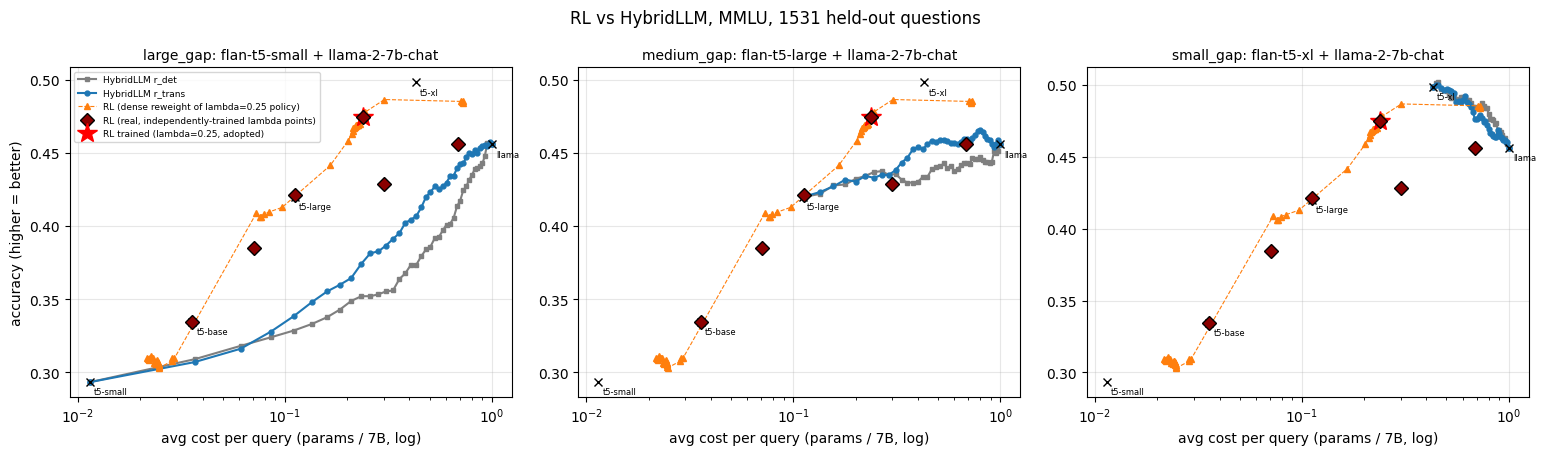

saved /home/bhavana.ravi/hybridllm_project/outputs/mmlu_quality_comparison.json


In [16]:
fig, axes = plt.subplots(1, len(pair_data), figsize=(5.2 * len(pair_data), 4.6), squeeze=False)
styles = {"r_det": ("tab:gray", "s-"), "r_trans": ("tab:blue", "o-")}
for ci, (label, d) in enumerate(pair_data.items()):
    ai = axes[0][ci]
    for lt, (c, fmt) in styles.items():
        pts = sorted(d["curves"][lt], key=lambda x: x["cost"])
        ai.plot([x["cost"] for x in pts], [x["accuracy"] for x in pts], fmt, color=c, ms=3.5, label=f"HybridLLM {lt}")
    pts = sorted(rl_curve, key=lambda x: x["cost"])
    ai.plot([x["cost"] for x in pts], [x["accuracy"] for x in pts], "^--", color="tab:orange", lw=0.8, ms=4,
            label=f"RL (dense reweight of lambda={LAMBDA_COST} policy)")
    ai.plot([r["cost"] for r in lambda_summary], [r["accuracy"] for r in lambda_summary], "D", color="darkred", ms=7,
            markeredgecolor="black", label="RL (real, independently-trained lambda points)", zorder=6)
    ai.plot(rl_point["cost"], rl_point["accuracy"], "*", color="red", ms=15, label=f"RL trained (lambda={LAMBDA_COST}, adopted)", zorder=5)
    for j, n in enumerate(MODEL_NAMES):
        ai.plot(COSTS[j], baselines[f"always {n}"]["accuracy"], "kx", ms=6)
        ai.annotate(n.replace("flan-t5-", "t5-").replace("llama-2-7b-chat", "llama"), (COSTS[j], baselines[f"always {n}"]["accuracy"]),
                    textcoords="offset points", xytext=(3, -9), fontsize=6)
    ai.set_xscale("log"); ai.grid(alpha=0.3); ai.set_xlabel("avg cost per query (params / 7B, log)")
    if ci == 0: ai.set_ylabel("accuracy (higher = better)")
    ai.set_title(f"{label}: {d['S']} + {d['L']}", fontsize=10)
axes[0][0].legend(fontsize=6.5)
plt.suptitle(f"RL vs HybridLLM, MMLU, {len(holdout)} held-out questions"); plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, f"{TAG}quality_vs_cost.png"), dpi=150); plt.show()

out = {"n_holdout": len(holdout), "n_train_hybrid": len(hyb_q), "lambda_rl": LAMBDA_COST, "lambda_eval_fixed": LAMBDA_EVAL,
       "lambda_sweep_summary": lambda_summary,
       "per_model": {n: {"cost": float(COSTS[j]), "accuracy": float(Q_hold_correct[:, j].mean()),
                          "mean_prob_correct": float(Q_hold_prob[:, j].mean())} for j, n in enumerate(MODEL_NAMES)},
       "baselines": baselines, "rl_point": rl_point, "rl_curve": rl_curve,
       "pairs": {label: {"small": d["S"], "large": d["L"], "label_stats": d["label_stats"],
                          "curves": d["curves"], "matched_cost": d["matched_cost"]} for label, d in pair_data.items()}}
with open(os.path.join(OUTPUT_DIR, f"{TAG}quality_comparison.json"), "w") as f:
    json.dump(out, f, indent=2)
print("saved", os.path.join(OUTPUT_DIR, f"{TAG}quality_comparison.json"))

## Tables A-F 

In [17]:
import csv
def save_csv(name, header, rows):
    with open(os.path.join(OUTPUT_DIR, f"{TAG}{name}.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(header); w.writerows(rows)

LB = MODEL_NAMES.index("llama-2-7b-chat")
def hybrid_choice_at_rl_cost(d, lt):
    pts = d["curves"][lt]; near = min(pts, key=lambda x: abs(x["cost"] - rl_point["cost"]))
    return np.where(d["p"][lt] >= near["theta"], d["S_IDX"], d["L_IDX"]), near

# ---- Table A: the five models ----
print("TABLE A: the five models on the held-out set")
hdr = ["model", "cost", "accuracy", "mean_P(correct)"]
rowsA = [[n, round(float(COSTS[j]), 3), round(float(Q_hold_correct[:, j].mean()), 3), round(float(Q_hold_prob[:, j].mean()), 3)]
         for j, n in enumerate(MODEL_NAMES)]
for r in [hdr] + rowsA: print("  " + " | ".join(f"{str(x):>16}" for x in r))
save_csv("tableA_models", hdr, rowsA)

# ---- Table B: RL vs HybridLLM at (nearly) the same serving cost ----
print("\nTABLE B: matched serving cost (HybridLLM operating point nearest to RL's cost)")
hdr = ["method", "cost", "accuracy", "share_to_llama", "utility"]
rowsB = [["Always Llama", *[round(baselines["always llama-2-7b-chat"][k], 3) for k in ["cost", "accuracy", "share_llama", "utility"]]],
         ["RL (trained)", *[round(rl_point[k], 3) for k in ["cost", "accuracy", "share_llama", "utility"]]]]
for label, d in pair_data.items():
    for lt in d["p"]:
        ch, near = hybrid_choice_at_rl_cost(d, lt); e = evaluate(ch)
        rowsB.append([f"Hybrid {label} {lt}", *[round(e[k], 3) for k in ["cost", "accuracy", "share_llama", "utility"]]])
for r in [hdr] + rowsB: print("  " + " | ".join(f"{str(x):>22}" for x in r))
save_csv("tableB_matched_cost", hdr, rowsB)

# ---- Table C: per-question head-to-head ----
print("\nTABLE C: per-question head-to-head, % of held-out questions (RL vs HybridLLM at matched cost)")
hdr = ["pair", "label", "both correct", "only RL correct", "only Hybrid correct", "both wrong"]
rowsC = []
correct_rl = Q_hold_correct[ar, rl_choice(LAMBDA_COST)] >= 0.5
for label, d in pair_data.items():
    for lt in d["p"]:
        ch, near = hybrid_choice_at_rl_cost(d, lt); correct_h = Q_hold_correct[ar, ch] >= 0.5
        rowsC.append([label, lt, *[round(100 * float(x.mean()), 1) for x in
                      [correct_rl & correct_h, correct_rl & ~correct_h, ~correct_rl & correct_h, ~correct_rl & ~correct_h]]])
for r in [hdr] + rowsC: print("  " + " | ".join(f"{str(x):>18}" for x in r))
save_csv("tableC_head_to_head", hdr, rowsC)

# ---- Table D: where each router sends questions ----
print("\nTABLE D: routing behaviour (% of held-out questions sent to each model)")
hdr = ["router"] + MODEL_NAMES
rowsD = [["RL (trained)"] + [round(100 * float((rl_choice(LAMBDA_COST) == j).mean()), 1) for j in range(N_ARMS)]]
for label, d in pair_data.items():
    for lt in d["p"]:
        ch, _ = hybrid_choice_at_rl_cost(d, lt)
        rowsD.append([f"Hybrid {label} {lt}"] + [round(100 * float((ch == j).mean()), 1) for j in range(N_ARMS)])
orc = np.array([int(np.argmax(r >= 0.5)) if (r >= 0.5).any() else int(np.argmax(Q_hold_prob[i])) for i, r in enumerate(Q_hold_correct)])
rowsD.append(["Oracle (cheapest correct)"] + [round(100 * float((orc == j).mean()), 1) for j in range(N_ARMS)])
for r in [hdr] + rowsD: print("  " + " | ".join(f"{str(x):>22}" for x in r))
save_csv("tableD_routing", hdr, rowsD)

# ---- Table E: total cost ----
print("\nTABLE E: total cost (raw params x calls), RL online over the whole pool vs HybridLLM label-building + holdout serving at matched cost")
try:
    Rj = json.load(open(os.path.join(OUTPUT_DIR, f"{TAG}rl_results.json")))
    rl_total_raw = float(Rj["total_cost_raw_params"])
except Exception as e:
    rl_total_raw = float("nan"); print("  (could not read RL total:", e, ")")
hdr = ["pair", "label_building_T", "serving_holdout_T", "hybrid_total_T", "RL_total_T", "hybrid/RL"]
rowsE = []
for label, d in pair_data.items():
    lb = len(hyb_q) * (PARAMS[d["S_IDX"]] + PARAMS[d["L_IDX"]])
    _, near = hybrid_choice_at_rl_cost(d, "r_trans"); serve = len(holdout) * near["cost"] * PARAMS.max()
    rowsE.append([label, round(lb / 1e12, 2), round(serve / 1e12, 2), round((lb + serve) / 1e12, 2),
                  round(rl_total_raw / 1e12, 2), round((lb + serve) / rl_total_raw, 2) if rl_total_raw == rl_total_raw else None])
for r in [hdr] + rowsE: print("  " + " | ".join(f"{str(x):>16}" for x in r))
save_csv("tableE_total_cost", hdr, rowsE)

# ---- Table F: example questions for a qualitative slide ----
print("\nTABLE F: examples where RL chose a cheaper model (saved to CSV; first 3 shown)")
ch_rl = rl_choice(LAMBDA_COST)
cands = [i for i in range(len(holdout)) if ch_rl[i] != LB and Q_hold_correct[i, ch_rl[i]] >= 0.5 and Q_hold_correct[i, LB] < 0.5]
fails = [i for i in range(len(holdout)) if ch_rl[i] != LB and Q_hold_correct[i, ch_rl[i]] < 0.5 and Q_hold_correct[i, LB] >= 0.5]
rowsF = []
for kind, ids in [("cheap model correct (Llama wrong)", cands[:4]), ("cheap model wrong (Llama correct)", fails[:3])]:
    for i in ids:
        m = MODEL_NAMES[ch_rl[i]]
        correct_letter = "ABCD"[holdout[i]["answer"]]
        rowsF.append([kind, holdout[i]["question"][:160].replace("\n", " "), m, round(float(Q_hold_prob[i, ch_rl[i]]), 3),
                      round(float(Q_hold_prob[i, LB]), 3), correct_letter])
save_csv("tableF_examples", ["case", "question", "RL_model", "RL_P(correct)", "llama_P(correct)", "correct_letter"], rowsF)
for r in rowsF[:3]: print("  ", r[0], "|", r[1][:80], "|", r[2], "| P(correct)", r[3], "vs llama", r[4])
print(f"\n(candidate counts: {len(cands)} good-cheap cases, {len(fails)} failed-cheap cases)")

TABLE A: the five models on the held-out set
             model |             cost |         accuracy |  mean_P(correct)
     flan-t5-small |            0.011 |            0.293 |            0.268
      flan-t5-base |            0.036 |            0.334 |            0.311
     flan-t5-large |            0.111 |             0.42 |            0.385
        flan-t5-xl |            0.429 |            0.498 |            0.465
   llama-2-7b-chat |              1.0 |            0.456 |             0.44

TABLE B: matched serving cost (HybridLLM operating point nearest to RL's cost)
                  method |                   cost |               accuracy |         share_to_llama |                utility
            Always Llama |                    1.0 |                  0.456 |                    1.0 |                 -0.588
            RL (trained) |                  0.238 |                  0.475 |                    0.0 |                 -0.169
  Hybrid large_gap r_det |                  

### NOTE: 
small_gap's HybridLLM router predicts flan-t5-xl with very high confidence for
nearly every question (BCE loss dropped to ~0.09-0.24), so its threshold sweep has no
intermediate operating points -- it only ever lands on cost=0.429 or cost=1.0. The
'HybridLLM better' verdict for this pair compares HybridLLM at ~80% MORE compute than
RL's matched point, not a fair same-cost comparison like large_gap/medium_gap got.